# Giorno 4, mattina: preprocessing, PCA e clustering

Obiettivo di oggi: saper usare la PCA e un modello supervisionato, e soprattutto saper
riconoscere quando il risultato non vale niente.

Stamattina l'analisi non supervisionata: nessuna etichetta, si cerca la struttura nei dati.
È la tecnica più usata su matrici biologiche e dati da sensore, ed è quella che vi chiedono
i revisori quando avete 20 variabili per campione.

## 0. Cella di avvio

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt

def trova_dati():
    for cand in [Path("../dati"), Path("dati"), Path("corso_python_CNR/dati")]:
        if cand.exists():
            return cand
    for radice in [Path(".."), Path("."), Path("corso_python_CNR")]:
        if (radice / "genera_dati.py").exists():
            sys.path.insert(0, str(radice.resolve()))
            from genera_dati import genera_tutto
            return genera_tutto(radice / "dati")
    raise FileNotFoundError("Cartella 'dati' non trovata: carica la cartella del corso.")

DATI = trova_dati()
mpl.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})
from cycler import cycler
mpl.rcParams["axes.prop_cycle"] = cycler(color=["#0072B2", "#D55E00", "#009E73", "#CC79A7", "#E69F00"])
import sklearn
print("scikit-learn", sklearn.__version__)

scikit-learn 1.9.0


---
## 1. Il flusso di lavoro

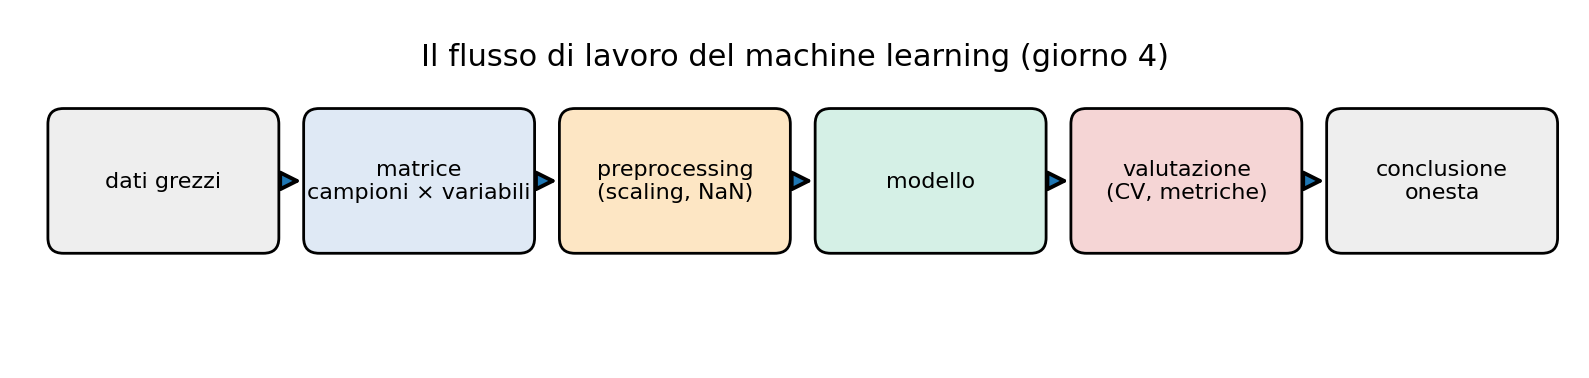

Ogni tappa ha una decisione dentro, e ogni decisione va scritta. La tappa che manca quasi
sempre nei manoscritti è l'ultima: una conclusione onesta su quanto ci si può fidare.

### Il dataset: campioni × variabili

60 campioni di materiale vegetale da tre siti. Per ognuno: 15 correnti lette a potenziali
fissi da un sensore elettrochimico (una "impronta" voltammetrica), più 5 variabili
chimico-fisiche. Le domande: i siti si distinguono dall'impronta? Quali variabili li distinguono?

In [2]:
df = pd.read_csv(DATI / "sensori_matrice.csv")
print(df.shape)
print(df["classe"].value_counts())
df.head(3)

(60, 22)
classe
Cascine        20
Vallombrosa    20
Maremma        20
Name: count, dtype: int64


,campione,i_-0.50V,i_-0.45V,i_-0.40V,i_-0.35V,i_-0.30V,i_-0.25V,i_-0.20V,i_-0.15V,i_-0.10V,...,i_+0.05V,i_+0.10V,i_+0.15V,i_+0.20V,pH,conducibilita_uS,umidita_%,clorofilla,fenoli_tot,classe
0,M001,1.075,0.274,1.432,2.085,1.752,3.111,2.999,1.331,0.971,...,1.359,0.932,1.569,1.173,5.856,375.813,50.206,33.514,11.850,Cascine
1,M006,0.614,1.626,0.716,1.912,2.310,3.717,2.300,1.266,1.434,...,0.983,0.484,-0.027,0.884,5.988,366.287,55.109,36.407,11.282,Cascine
2,M037,1.405,1.517,0.193,-0.279,1.180,2.758,4.701,3.720,1.685,...,0.625,0.195,2.033,1.875,6.904,355.540,55.775,35.059,15.328,Vallombrosa


In [3]:
df.describe().T.round(2).head(8)

,count,mean,std,min,25%,50%,75%,max
i_-0.50V,60.0,0.93,0.81,-0.78,0.32,0.90,1.47,2.91
i_-0.45V,60.0,0.93,0.89,-1.00,0.39,0.94,1.55,2.78
i_-0.40V,60.0,1.00,0.95,-0.90,0.24,1.08,1.64,3.18
i_-0.35V,60.0,1.12,0.96,-0.99,0.45,1.23,1.74,2.73
i_-0.30V,60.0,1.61,1.34,-1.58,0.63,1.60,2.44,4.80
i_-0.25V,60.0,2.42,1.40,-0.06,1.15,2.29,3.55,5.09
i_-0.20V,59.0,2.84,1.31,-0.62,2.02,2.95,3.82,5.32
i_-0.15V,60.0,2.70,1.16,0.01,2.02,2.63,3.71,4.66


---
## 2. Preparare la matrice `X`

scikit-learn vuole:
- `X`: un array/DataFrame numerico, righe = campioni, colonne = variabili (*features*);
- `y` (solo nel supervisionato): un vettore di etichette, lungo quanto le righe di `X`.

Tutto ciò che non è una variabile di misura (identificativi, etichette, note) **sta fuori da X**.
Se ci finisce dentro l'etichetta di classe, il modello "predice" perfettamente: è un errore
classico, e il risultato non vale niente.

In [4]:
variabili = [c for c in df.columns if c not in ("campione", "classe")]
X = df[variabili]
y = df["classe"]
print(X.shape, y.shape)
print("mancanti per colonna (solo dove > 0):")
print(X.isna().sum()[X.isna().sum() > 0])

(60, 20) (60,)
mancanti per colonna (solo dove > 0):
i_-0.20V      1
pH            1
fenoli_tot    1
dtype: int64


### Valori mancanti in ottica ML

Con 60 campioni non si buttano via righe per un valore mancante. Si **imputa**: la mediana
della colonna è la scelta robusta di default. Attenzione però: la mediana va calcolata sui
dati di addestramento, non su tutti, altrimenti il test set "sa" qualcosa del train. Lo
risolveremo nel pomeriggio con `Pipeline`; per ora, con analisi non supervisionata su tutto
il dataset, il problema non si pone.

In [5]:
from sklearn.impute import SimpleImputer

imputer = SimpleImputer(strategy="median")
X_imp = imputer.fit_transform(X)                  # array NumPy
X_imp = pd.DataFrame(X_imp, columns=variabili)    # ritorno a DataFrame per tenere i nomi
print("mancanti dopo imputazione:", X_imp.isna().sum().sum())

mancanti dopo imputazione: 0


---
## 3. Standardizzazione: perché è obbligatoria

Le variabili hanno unità e scale diverse: la conducibilità vale centinaia di µS, il pH sta
fra 6 e 7, le correnti fra 0 e 5 µA. La PCA cerca le direzioni di massima varianza: senza
standardizzare, la varianza è tutta nella conducibilità, e la PCA vi restituisce la
conducibilità. Idem per k-means e per qualunque metodo basato su distanze.

`StandardScaler`: ogni colonna → media 0, deviazione standard 1 ($z = (x - \mu)/\sigma$).
Per capire cosa fa davvero serve un richiamo di NumPy: array a due dimensioni, `axis` e broadcasting.

### Un richiamo di NumPy che serve adesso: righe, colonne e `axis`

`shape = (righe, colonne)`. Si indicizza con `[riga, colonna]`, e `:` significa "tutte".
Le operazioni statistiche accettano `axis=`: `axis=0` lavora lungo le righe (cioè *per colonna*),
`axis=1` lungo le colonne (cioè *per riga*). La prima volta confonde tutti: `axis` indica la
dimensione che viene consumata.

In [6]:
# 4 repliche (righe) x 3 concentrazioni (colonne)
M = np.array([[0.58, 1.02, 2.31],
              [0.61, 0.99, 2.28],
              [0.55, 1.05, 2.35],
              [0.60, 1.01, 2.30]])
print(M.shape)
print(M[0, :])          # prima riga (prima replica)
print(M[:, 2])          # terza colonna (tutte le repliche alla terza concentrazione)
print(M[1:3, :2])       # sottomatrice

(4, 3)
[0.58 1.02 2.31]
[2.31 2.28 2.35 2.3 ]
[[0.61 0.99]
 [0.55 1.05]]


In [7]:
print("media per colonna (per concentrazione):", M.mean(axis=0))
print("media per riga    (per replica):       ", M.mean(axis=1))
print("media di tutto:", M.mean())

media per colonna (per concentrazione): [0.585  1.0175 2.31  ]
media per riga    (per replica):        [1.30333333 1.29333333 1.31666667 1.30333333]
media di tutto: 1.3041666666666665


### Broadcasting

Sottrarre a ogni colonna la propria media, dividere ogni colonna per la propria deviazione
standard: NumPy "stira" automaticamente l'array più piccolo (forma `(3,)`) su tutte le righe
di quello grande (forma `(4, 3)`).

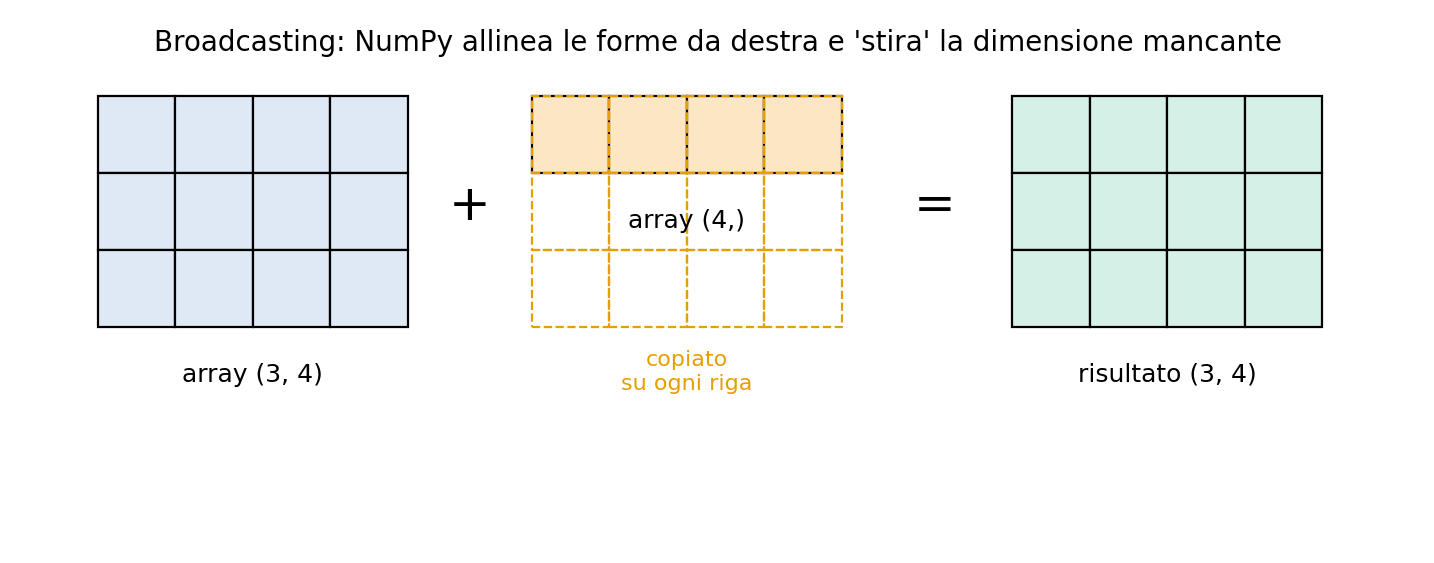

In [8]:
print(M - M.mean(axis=0))           # (4,3) - (3,) -> ogni colonna centrata sulla sua media

[[-5.0000000e-03  2.5000000e-03  4.4408921e-16]
 [ 2.5000000e-02 -2.7500000e-02 -3.0000000e-02]
 [-3.5000000e-02  3.2500000e-02  4.0000000e-02]
 [ 1.5000000e-02 -7.5000000e-03 -1.0000000e-02]]


La standardizzazione è esattamente questo: `(X - X.mean(axis=0)) / X.std(axis=0)`.
`StandardScaler` fa la stessa cosa (con la deviazione standard "di popolazione", `ddof=0`),
ma ricorda medie e deviazioni standard per applicarle a dati nuovi.

In [9]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_std = pd.DataFrame(scaler.fit_transform(X_imp), columns=variabili)
print("varianza per colonna PRIMA (le 5 più grandi):")
print(X_imp.var().sort_values(ascending=False).head(5).round(1))
print("\nvarianza per colonna DOPO:", X_std.var().round(2).unique())

varianza per colonna PRIMA (le 5 più grandi):
conducibilita_uS    8656.0
umidita_%             27.3
clorofilla            19.4
fenoli_tot            13.4
i_-0.10V               2.6
dtype: float64

varianza per colonna DOPO: [1.02]


In [10]:
# Verifica: lo scaler è il broadcasting di sopra, nient'altro
A = X_imp.to_numpy()
z_a_mano = (A - A.mean(axis=0)) / A.std(axis=0)          # std con ddof=0, come StandardScaler
print("identici a StandardScaler?", np.allclose(z_a_mano, X_std.to_numpy()))
print("medie (prime 3 colonne):", scaler.mean_[:3].round(3))

identici a StandardScaler? True
medie (prime 3 colonne): [0.927 0.932 0.996]


### L'interfaccia di scikit-learn: `fit`, `transform`, `predict`

Avete appena visto lo schema che vale per tutto scikit-learn:

| Metodo | Cosa fa | Chi ce l'ha |
|---|---|---|
| `.fit(X)` | impara dai dati (medie, sd, componenti, alberi…) | tutti |
| `.transform(X)` | applica la trasformazione imparata | scaler, imputer, PCA |
| `.fit_transform(X)` | i due insieme | idem |
| `.predict(X)` | produce una previsione | modelli |
| `.fit_predict(X)` | i due insieme | clustering |

La separazione `fit` / `transform` è quello che vi permette, nel pomeriggio, di imparare sul
train e applicare sul test senza contaminazione.

### Cosa succede senza scaling: dimostrazione

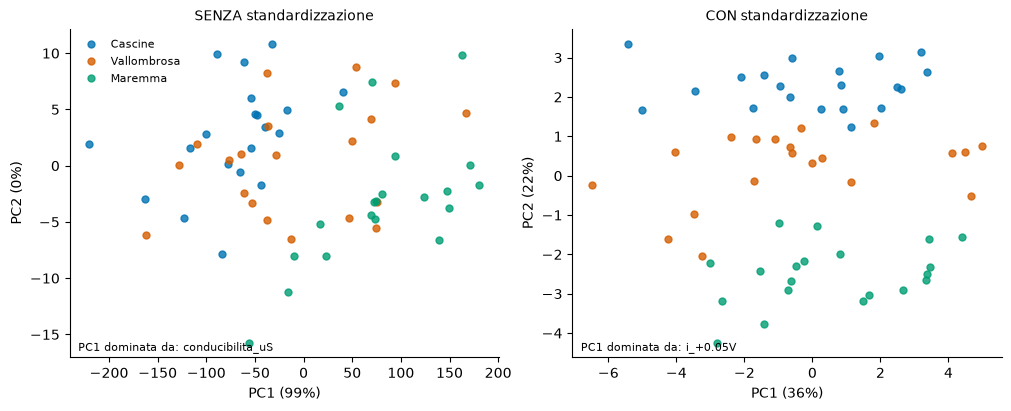

In [11]:
from sklearn.decomposition import PCA

fig, (a1, a2) = plt.subplots(1, 2, figsize=(10, 4), constrained_layout=True)
for ax, dati, titolo in [(a1, X_imp, "SENZA standardizzazione"), (a2, X_std, "CON standardizzazione")]:
    pca = PCA(n_components=2).fit(dati)
    S = pca.transform(dati)
    for cl in y.unique():
        ax.plot(S[y == cl, 0], S[y == cl, 1], "o", ms=5, alpha=0.8, label=cl)
    ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.0%})")
    ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.0%})")
    ax.set_title(titolo, fontsize=10)
    # quale variabile domina PC1?
    dom = variabili[np.argmax(np.abs(pca.components_[0]))]
    ax.text(0.02, 0.02, f"PC1 dominata da: {dom}", transform=ax.transAxes, fontsize=8)
a1.legend(frameon=False, fontsize=8)
plt.show()

A sinistra PC1 spiega il 99 % della varianza, ed è solo la conducibilità in µS. A destra
la PCA usa tutte le variabili. Si standardizza sempre, salvo quando le variabili hanno tutte
la stessa unità e la scala è informativa (per esempio negli spettri): lì si valuta caso per caso.

---
## 4. PCA: varianza spiegata, scores, loadings

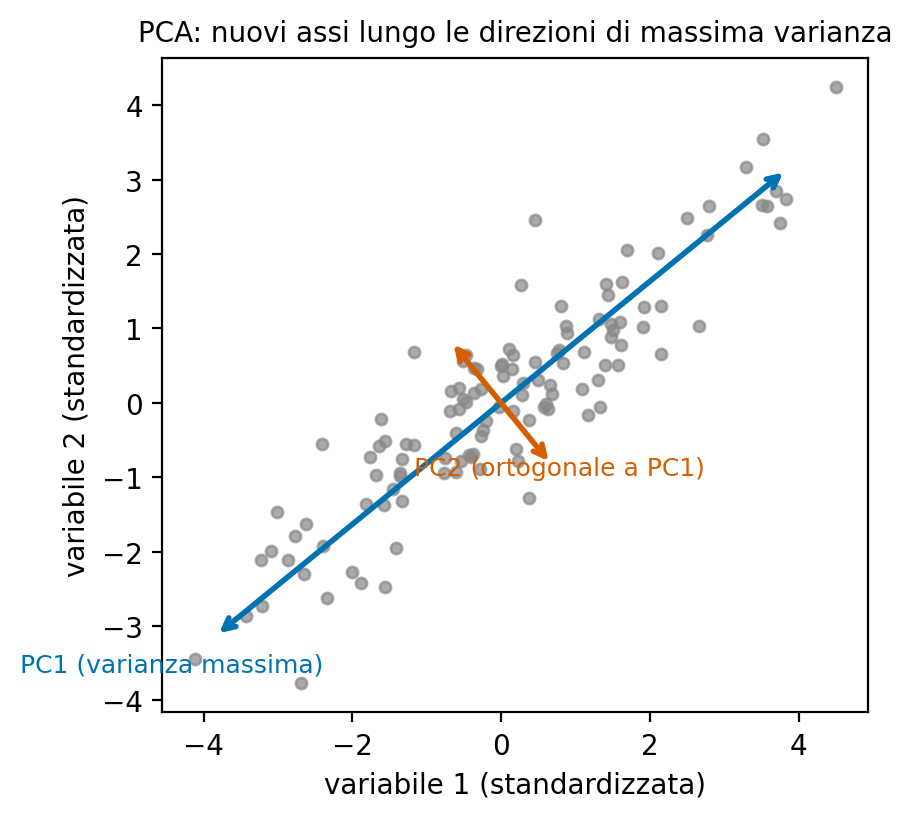

La PCA ruota gli assi: le nuove coordinate (componenti principali) sono combinazioni
lineari delle variabili originali, ordinate per varianza spiegata. Tre uscite da leggere,
sempre in quest'ordine:

1. **Varianza spiegata** per componente: quante componenti servono? (grafico a gomito)
2. **Scores**: le coordinate dei campioni sulle componenti. È il grafico che mostra se i
   gruppi si separano.
3. **Loadings**: il peso di ogni variabile su ogni componente. È il grafico che dice
   *perché* si separano: senza i loadings la PCA resta una figura decorativa.

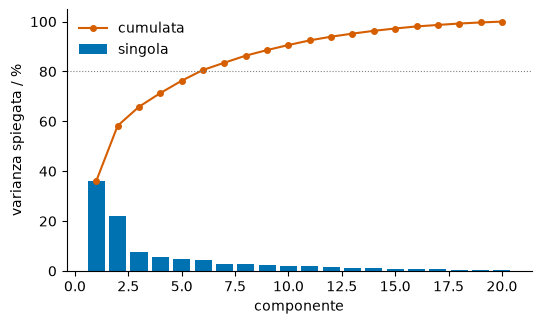

prime 4 componenti: [36.1 22.1  7.6  5.5] % ; cumulata: [36.1 58.2 65.8 71.3]


In [12]:
pca = PCA().fit(X_std)
ve = pca.explained_variance_ratio_

fig, ax = plt.subplots(figsize=(6, 3.4))
ax.bar(range(1, len(ve) + 1), ve * 100, label="singola")
ax.plot(range(1, len(ve) + 1), np.cumsum(ve) * 100, "o-", color="#D55E00", ms=4, label="cumulata")
ax.axhline(80, color="gray", lw=0.8, ls=":")
ax.set_xlabel("componente"); ax.set_ylabel("varianza spiegata / %"); ax.legend(frameon=False)
plt.show()
print("prime 4 componenti:", np.round(ve[:4] * 100, 1), "% ; cumulata:", np.round(np.cumsum(ve)[:4] * 100, 1))

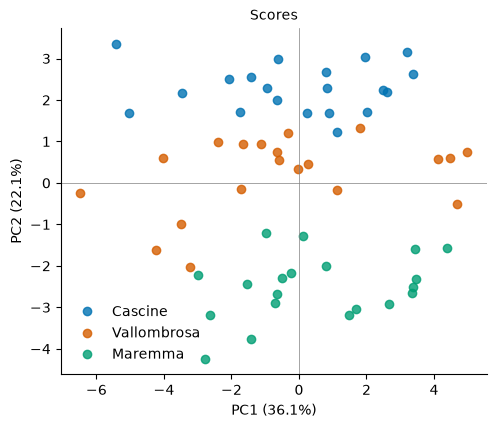

In [13]:
scores = pd.DataFrame(pca.transform(X_std)[:, :3], columns=["PC1", "PC2", "PC3"])
scores["classe"] = y.values
scores["campione"] = df["campione"].values

fig, ax = plt.subplots(figsize=(5.5, 4.5))
for cl in y.unique():
    s = scores[scores["classe"] == cl]
    ax.plot(s["PC1"], s["PC2"], "o", ms=6, alpha=0.8, label=cl)
ax.axhline(0, color="gray", lw=0.5); ax.axvline(0, color="gray", lw=0.5)
ax.set_xlabel(f"PC1 ({ve[0]:.1%})"); ax.set_ylabel(f"PC2 ({ve[1]:.1%})")
ax.legend(frameon=False); ax.set_title("Scores", fontsize=10)
plt.show()

### Interpretazione dei loadings

`pca.components_` ha forma (componenti, variabili). La riga 0 sono i pesi di PC1. Un peso
positivo grande: la variabile *cresce* lungo PC1; negativo: decresce; vicino a zero: non c'entra.

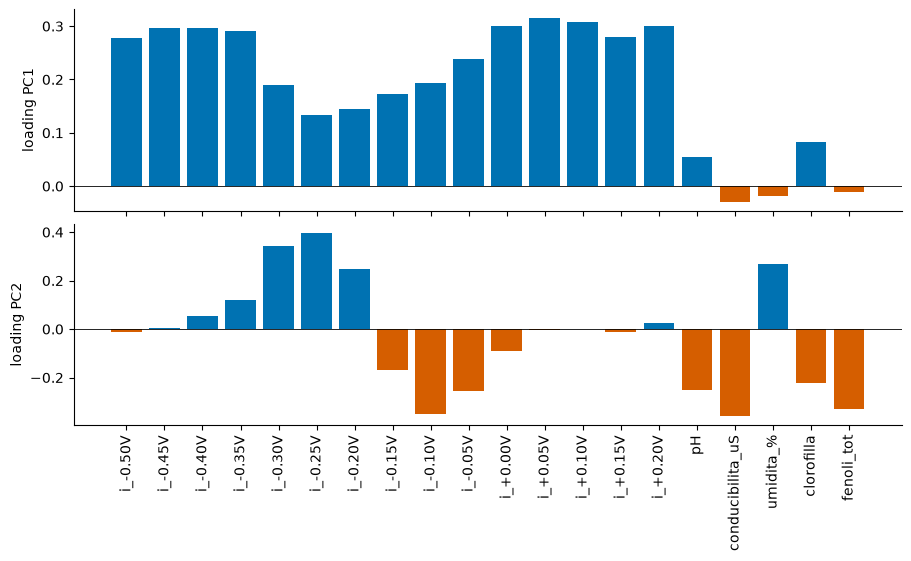

Le 5 variabili che pesano di più su PC1 (con segno):
{'i_+0.05V': 0.314, 'i_+0.10V': 0.308, 'i_+0.00V': 0.301, 'i_+0.20V': 0.3, 'i_-0.40V': 0.297}
Le 5 variabili che pesano di più su PC2 (con segno):
{'i_-0.25V': 0.396, 'conducibilita_uS': -0.359, 'i_-0.10V': -0.348, 'i_-0.30V': 0.344, 'fenoli_tot': -0.329}


In [14]:
loadings = pd.DataFrame(pca.components_[:3].T, index=variabili, columns=["PC1", "PC2", "PC3"])

fig, (a1, a2) = plt.subplots(2, 1, figsize=(9, 5.5), sharex=True, constrained_layout=True)
for ax, pc in [(a1, "PC1"), (a2, "PC2")]:
    colori = ["#0072B2" if v >= 0 else "#D55E00" for v in loadings[pc]]
    ax.bar(loadings.index, loadings[pc], color=colori)
    ax.axhline(0, color="black", lw=0.6)
    ax.set_ylabel(f"loading {pc}")
a2.tick_params(axis="x", rotation=90)
plt.show()

for pc in ["PC1", "PC2"]:
    print(f"Le 5 variabili che pesano di più su {pc} (con segno):")
    print(loadings[pc].reindex(loadings[pc].abs().sort_values(ascending=False).head(5).index).round(3).to_dict())

Come si legge, senza bisogno di sapere come funziona il sensore:

- **PC1** ha pesi positivi e simili su *tutti* i 15 canali di corrente e quasi nulli sulle 5
  variabili chimico-fisiche. È uno spostamento comune che alza o abbassa tutti i canali
  insieme in un campione: la firma tipica di un effetto di misura (deriva, lotto, giornata) e non
  della composizione del campione. Spiega il 36 % della varianza e non separa i siti: guardate
  gli scores, i gruppi si distinguono lungo PC2, non lungo PC1.
- **PC2** contrappone i canali attorno a −0.25 V (pesi positivi) a quelli attorno a −0.10 V
  (pesi negativi), e con questi ultimi conducibilità e fenoli: dice quali canali portano il
  segnale più alto, e questo cambia da un sito all'altro insieme alla chimica. Cascine sta in
  alto, Maremma (segnale spostato verso −0.10 V, più conducibilità e fenoli) in basso.

Due lezioni: la componente più grande non è necessariamente quella interessante; e senza i
loadings non avreste saputo che PC1 è un effetto comune a tutti i canali, non un'informazione sui siti.

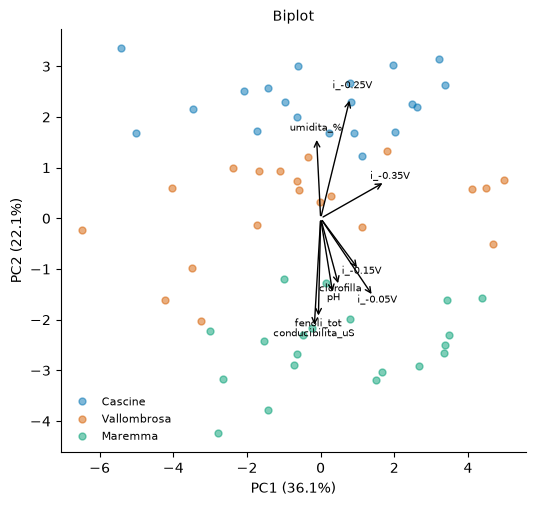

In [15]:
# Biplot: scores e loadings sovrapposti (le frecce vanno riscalate per stare nel grafico)
fig, ax = plt.subplots(figsize=(6, 5.5))
for cl in y.unique():
    s = scores[scores["classe"] == cl]
    ax.plot(s["PC1"], s["PC2"], "o", ms=5, alpha=0.5, label=cl)
scala = 6
for var in ["i_-0.35V", "i_-0.25V", "i_-0.15V", "i_-0.05V", "pH", "conducibilita_uS", "umidita_%", "clorofilla", "fenoli_tot"]:
    lx, ly = loadings.loc[var, "PC1"] * scala, loadings.loc[var, "PC2"] * scala
    ax.annotate("", xy=(lx, ly), xytext=(0, 0), arrowprops=dict(arrowstyle="->", color="black", lw=1))
    ax.text(lx * 1.08, ly * 1.08, var, fontsize=7, ha="center")
ax.set_xlabel(f"PC1 ({ve[0]:.1%})"); ax.set_ylabel(f"PC2 ({ve[1]:.1%})"); ax.legend(frameon=False, fontsize=8)
ax.set_title("Biplot", fontsize=10)
plt.show()

### Esercizio 7.1: PCA sulle sole correnti (livello 2)

Le 5 variabili chimico-fisiche potrebbero essere quelle che separano i siti, e il sensore
c'entrare poco. Verificate: rifate la PCA usando solo le 15 colonne `i_…V`
(imputazione → standardizzazione → PCA). I siti si separano ancora? Quanto spiega PC1?
Quali potenziali pesano di più?

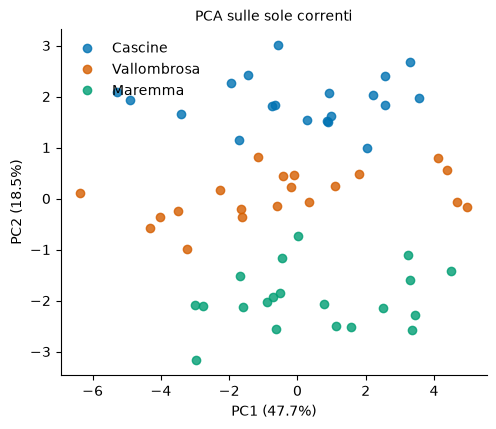

PC1: {'i_+0.05V': 0.32, 'i_+0.10V': 0.31, 'i_+0.00V': 0.3}
PC2: {'i_-0.25V': 0.51, 'i_-0.10V': -0.46, 'i_-0.30V': 0.43}


In [16]:
# ESERCIZIO 7.1 (livello 2)
correnti = [c for c in variabili if c.startswith("i_")]
# 1. X_c = df[correnti]; imputa; standardizza
# 2. PCA, scores plot per classe
# 3. loadings di PC1 e PC2: le 3 variabili con peso assoluto maggiore
# --- SOLUZIONE ---
X_c = pd.DataFrame(StandardScaler().fit_transform(SimpleImputer(strategy="median").fit_transform(df[correnti])), columns=correnti)
pca_c = PCA().fit(X_c)
S_c = pca_c.transform(X_c)
fig, ax = plt.subplots(figsize=(5.5, 4.5))
for cl in y.unique():
    ax.plot(S_c[y == cl, 0], S_c[y == cl, 1], "o", ms=6, alpha=0.8, label=cl)
ax.set_xlabel(f"PC1 ({pca_c.explained_variance_ratio_[0]:.1%})"); ax.set_ylabel(f"PC2 ({pca_c.explained_variance_ratio_[1]:.1%})")
ax.legend(frameon=False); ax.set_title("PCA sulle sole correnti", fontsize=10)
plt.show()
for k in (0, 1):
    l = pd.Series(pca_c.components_[k], index=correnti)
    print(f"PC{k+1}:", l.reindex(l.abs().sort_values(ascending=False).head(3).index).round(2).to_dict())

> Sì, si separano ancora (su PC2), quindi i 15 canali da soli portano l'informazione. E PC1 sale
> al 48 %: è lo stesso spostamento comune visto prima, ancora più dominante senza le variabili
> chimico-fisiche. Succede spesso con segnali multicanale (spettri, sensori, array), e la soluzione
> tipica è una **normalizzazione per campione**: sottrarre a ogni riga la sua media (centering per
> riga) prima della PCA. Lo faremo nell'esercizio 7.2: `X_c.sub(X_c.mean(axis=1), axis=0)`.

---
## 5. Clustering: k-means e gerarchico, e le loro insidie

Il clustering raggruppa i campioni senza etichette. Serve quando le classi non le
conoscete; qui le conosciamo, e ci serve proprio per vedere quanto un clustering possa
sbagliare pur producendo gruppi dall'aspetto convincente.

**k-means**: si sceglie $k$, l'algoritmo trova $k$ centri e assegna ogni punto al più vicino.
Insidie: dovete scegliere $k$ voi; assume gruppi sferici e di dimensione simile; il risultato
dipende dall'inizializzazione (`n_init=10` la ripete e tiene la migliore); va usato sempre su
dati standardizzati.

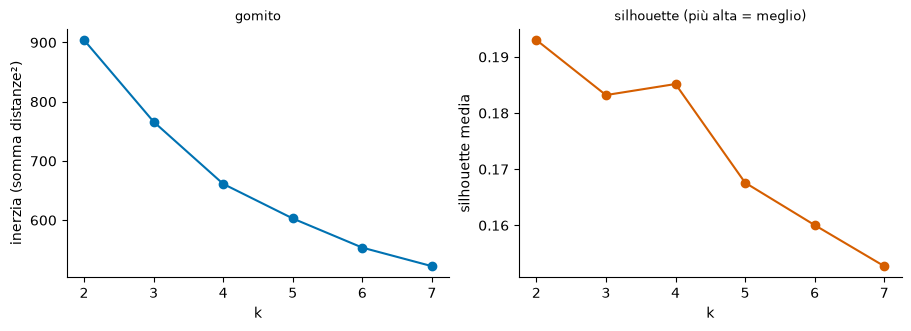

In [17]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score

inerzie, sil = [], []
for k in range(2, 8):
    km = KMeans(n_clusters=k, n_init=10, random_state=0).fit(X_std)
    inerzie.append(km.inertia_)
    sil.append(silhouette_score(X_std, km.labels_))

fig, (a1, a2) = plt.subplots(1, 2, figsize=(9, 3.2), constrained_layout=True)
a1.plot(range(2, 8), inerzie, "o-"); a1.set_xlabel("k"); a1.set_ylabel("inerzia (somma distanze²)"); a1.set_title("gomito", fontsize=9)
a2.plot(range(2, 8), sil, "o-", color="#D55E00"); a2.set_xlabel("k"); a2.set_ylabel("silhouette media"); a2.set_title("silhouette (più alta = meglio)", fontsize=9)
plt.show()

In [18]:
km = KMeans(n_clusters=3, n_init=10, random_state=0).fit(X_std)
tabella = pd.crosstab(y, km.labels_, rownames=["sito vero"], colnames=["cluster"])
print(tabella)
print(f"\nadjusted Rand index (1 = coincidenza perfetta, 0 = casuale): {adjusted_rand_score(y, km.labels_):.2f}")

cluster       0   1   2
sito vero              
Cascine      11   0   9
Maremma       3  17   0
Vallombrosa   8   0  12

adjusted Rand index (1 = coincidenza perfetta, 0 = casuale): 0.36


I cluster non sono le classi: Maremma viene isolata, ma Cascine e Vallombrosa finiscono
spalmate su due cluster che le mescolano. Senza le etichette non ve ne accorgereste. Il
clustering segue la struttura di varianza dominante, e qui la dominante (PC1) è lo spostamento
comune a tutti i canali, che con i siti non c'entra.

### Clustering gerarchico

> *Facoltativo: si può saltare se si è in ritardo.*

Il clustering gerarchico non richiede $k$ a priori; costruisce un albero (dendrogramma) unendo
progressivamente i campioni più vicini. Si "taglia" l'albero all'altezza che si vuole.

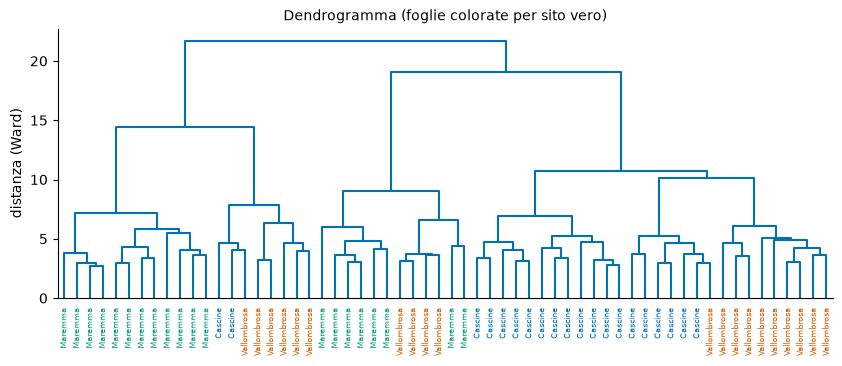

cluster gerarchico   1  2   3
sito vero                    
Cascine              2  0  18
Maremma             12  8   0
Vallombrosa          6  4  10
ARI: 0.28


In [19]:
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster

Z = linkage(X_std, method="ward")
fig, ax = plt.subplots(figsize=(10, 3.5))
colori_classe = {"Cascine": "#0072B2", "Vallombrosa": "#D55E00", "Maremma": "#009E73"}
dn = dendrogram(Z, labels=y.values, leaf_font_size=6, ax=ax, color_threshold=0)
for lbl in ax.get_xmajorticklabels():
    lbl.set_color(colori_classe[lbl.get_text()])
ax.set_ylabel("distanza (Ward)")
ax.set_title("Dendrogramma (foglie colorate per sito vero)", fontsize=10)
plt.show()

etichette_h = fcluster(Z, t=3, criterion="maxclust")
print(pd.crosstab(y, etichette_h, rownames=["sito vero"], colnames=["cluster gerarchico"]))
print(f"ARI: {adjusted_rand_score(y, etichette_h):.2f}")

### Esercizio 7.2: clustering dopo la normalizzazione per campione (livello 2)

Ripetete k-means (k = 3) sulle sole correnti, dopo aver sottratto a ogni campione la
media dei suoi 15 canali (normalizzazione per campione, *centering per riga*: toglie lo
spostamento comune di PC1), poi standardizzazione. Confrontate
con i siti veri: la tabella di contingenza e l'ARI migliorano?

In [20]:
# ESERCIZIO 7.2 (livello 2)
# 1. X_cd = df[correnti] imputato; sottrai la media per riga (centering per riga: .sub(..., axis=0))
# 2. standardizza
# 3. KMeans(3) -> crosstab con y, ARI
# --- SOLUZIONE ---
X_cd = pd.DataFrame(SimpleImputer(strategy="median").fit_transform(df[correnti]), columns=correnti)
X_cd = X_cd.sub(X_cd.mean(axis=1), axis=0)
X_cd = StandardScaler().fit_transform(X_cd)
km2 = KMeans(n_clusters=3, n_init=10, random_state=0).fit(X_cd)
print(pd.crosstab(y, km2.labels_, rownames=["sito vero"], colnames=["cluster"]))
print(f"ARI: {adjusted_rand_score(y, km2.labels_):.2f}")

cluster       0   1   2
sito vero              
Cascine      17   0   3
Maremma       0  20   0
Vallombrosa   0   0  20
ARI: 0.86


### Esercizio 7.3 (facoltativo): campioni con repliche (livello 2)

> *Facoltativo: si può saltare se si è in ritardo. È il dataset del progetto di oggi pomeriggio.*

`dataset_features_campioni.csv` ha 36 campioni misurati in 3 repliche ciascuno (108 righe),
45 variabili `feature_…` e 3 classi. Fate la PCA standardizzata e guardate gli scores due volte:

1. colorati per **classe**: le classi si separano?
2. con le 3 repliche di ogni campione **unite da una linea**: le repliche stanno vicine?

Poi mettete un numero su quello che vedete: nello spazio standardizzato, la distanza media fra
repliche dello **stesso campione**, e quella fra campioni **diversi della stessa classe**.
Cosa vi aspettate che succeda se, nella validazione crociata, una replica finisce nel train e
un'altra nel test? Scrivetelo in un commento: oggi pomeriggio lo verificheremo.

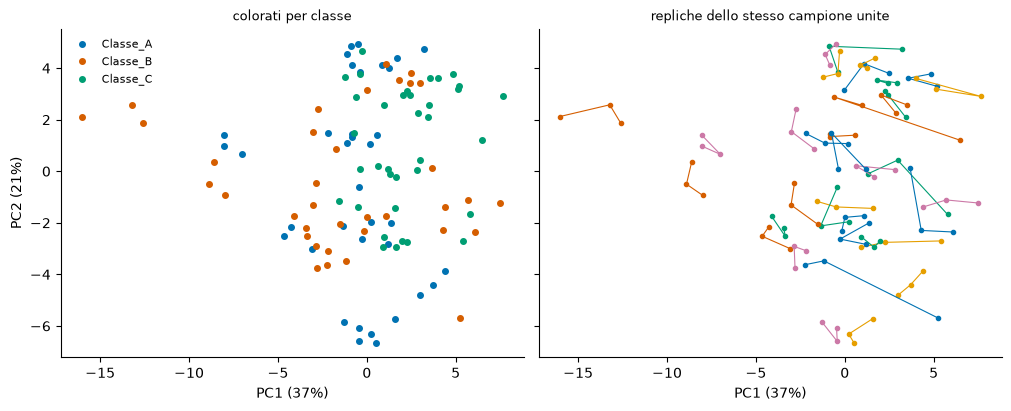

repliche dello stesso campione:       4.91
campioni diversi, stessa classe:      8.89
campioni di classi diverse:           9.18


In [21]:
# ESERCIZIO 7.3 (facoltativo, livello 2)
from scipy.spatial.distance import pdist, squareform
dr = pd.read_csv(DATI / "dataset_features_campioni.csv")
feat = [c for c in dr.columns if c.startswith("feature_")]
#> Zr = StandardScaler().fit_transform(dr[feat])
#> Sr = PCA(n_components=2).fit_transform(____)
#> fig, (a1, a2) = plt.subplots(1, 2, figsize=(10, 4), sharex=True, sharey=True)
#> for cl in sorted(dr["classe"].unique()):
#>     m = (dr["classe"] == ____).values
#>     a1.plot(Sr[m, 0], Sr[m, 1], "o", ms=4, label=cl)
#> for camp, righe in dr.groupby("campione").groups.items():
#>     a2.plot(Sr[righe, 0], Sr[righe, 1], "-o", ms=3, lw=0.8)     # le 3 repliche, unite
#> a1.legend(frameon=False, fontsize=8)
#> plt.show()
#>
#> D = squareform(pdist(Zr))                                        # distanze fra tutte le righe
#> stesso_camp = dr["campione"].to_numpy()[:, None] == dr["campione"].to_numpy()[None, :]
#> stessa_cl = dr["classe"].to_numpy()[:, None] == dr["classe"].to_numpy()[None, :]
#> fuori_diag = ~np.eye(len(dr), dtype=bool)
#> print("repliche dello stesso campione:      ", D[stesso_camp & fuori_diag].mean().round(2))
#> print("campioni diversi, stessa classe:     ", D[____ & ~stesso_camp].mean().round(2))
# --- SOLUZIONE ---
Zr = StandardScaler().fit_transform(dr[feat])
pca_r = PCA(n_components=2).fit(Zr)
Sr = pca_r.transform(Zr)
fig, (a1, a2) = plt.subplots(1, 2, figsize=(10, 4), sharex=True, sharey=True, constrained_layout=True)
for cl in sorted(dr["classe"].unique()):
    m = (dr["classe"] == cl).values
    a1.plot(Sr[m, 0], Sr[m, 1], "o", ms=4, label=cl)
for camp, righe in dr.groupby("campione").groups.items():
    a2.plot(Sr[righe, 0], Sr[righe, 1], "-o", ms=3, lw=0.8)
a1.set_title("colorati per classe", fontsize=9); a2.set_title("repliche dello stesso campione unite", fontsize=9)
for ax in (a1, a2):
    ax.set_xlabel(f"PC1 ({pca_r.explained_variance_ratio_[0]:.0%})")
a1.set_ylabel(f"PC2 ({pca_r.explained_variance_ratio_[1]:.0%})")
a1.legend(frameon=False, fontsize=8)
plt.show()

D = squareform(pdist(Zr))
stesso_camp = dr["campione"].to_numpy()[:, None] == dr["campione"].to_numpy()[None, :]
stessa_cl = dr["classe"].to_numpy()[:, None] == dr["classe"].to_numpy()[None, :]
fuori_diag = ~np.eye(len(dr), dtype=bool)
print("repliche dello stesso campione:      ", D[stesso_camp & fuori_diag].mean().round(2))
print("campioni diversi, stessa classe:     ", D[stessa_cl & ~stesso_camp].mean().round(2))
print("campioni di classi diverse:          ", D[~stessa_cl].mean().round(2))
# Commento: le repliche sono molto più vicine fra loro che a qualunque altro campione, anche della
# stessa classe. Se una replica sta nel train e un'altra nel test, il modello la "riconosce" e
# indovina la classe senza aver imparato niente sulla classe: l'accuratezza in CV sarà gonfiata.

> Nel pomeriggio vedremo l'altra faccia di questa storia: con molte variabili e pochi campioni,
> scegliere le variabili guardando le etichette produce separazioni (e accuratezze) perfette
> anche su puro rumore. Lo vedremo dal vivo con la validazione crociata.

---
## Riepilogo della mattina

1. `X` = solo variabili di misura; identificativi ed etichette restano fuori.
2. Mancanti: imputare (mediana), non scartare campioni.
3. Standardizzare sempre prima di PCA, k-means e di qualunque metodo che usi distanze.
4. PCA: varianza spiegata → scores → loadings. Senza loadings non c'è interpretazione.
5. Dati multicanale: cercate la componente "comune a tutti i canali" (effetto di misura) prima di
   quella che vi interessa; la normalizzazione per campione la toglie.
6. Clustering: bello, ma i cluster non sono le classi; verificate con ARI quando potete.
7. Una PCA o un clustering che "separa bene" non è una prova: nel pomeriggio vedremo come si valuta onestamente.

---
*Riferimento: Scientific Python Lectures, capitolo scikit-learn (CC-BY 4.0).*